<StringArray>
[   'disclosed_investment',    'estimated_investment',
 'num_patent_applications',      'num_patent_granted',
            'num_articles',           'num_citations']
Length: 6, dtype: str


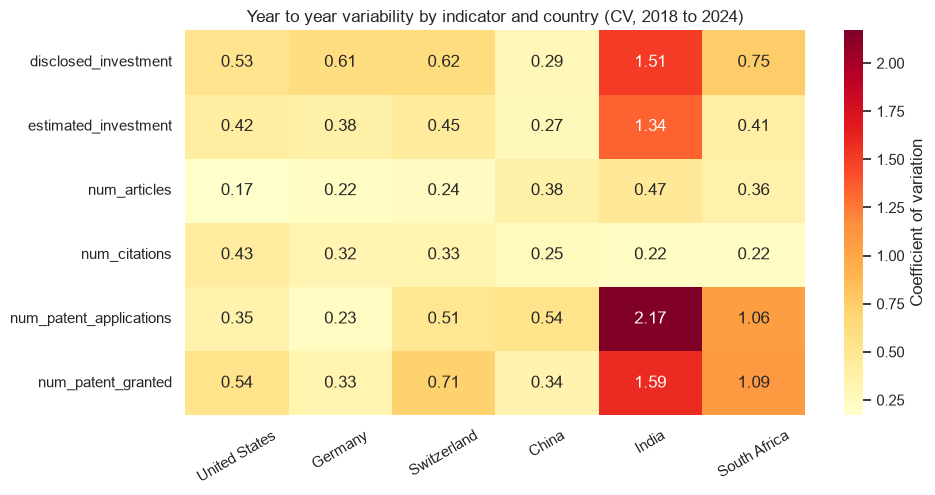

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

stats = pd.read_csv("clean-pt2/summary_statistics.csv")
order = ["United States", "Germany", "Switzerland", "China", "India", "South Africa"]

print(stats["indicator"].unique())

cv = stats.pivot(index="indicator", columns="country", values="CV")[order]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "Coefficient of variation"}, ax=ax)
ax.set_title("Year to year variability by indicator and country (CV, 2018 to 2024)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=30)
fig.savefig(OUT / "summary_cv_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [3]:
COLOURS = {"Developed": "#1f77b4", "Developing": "#d95f02"}

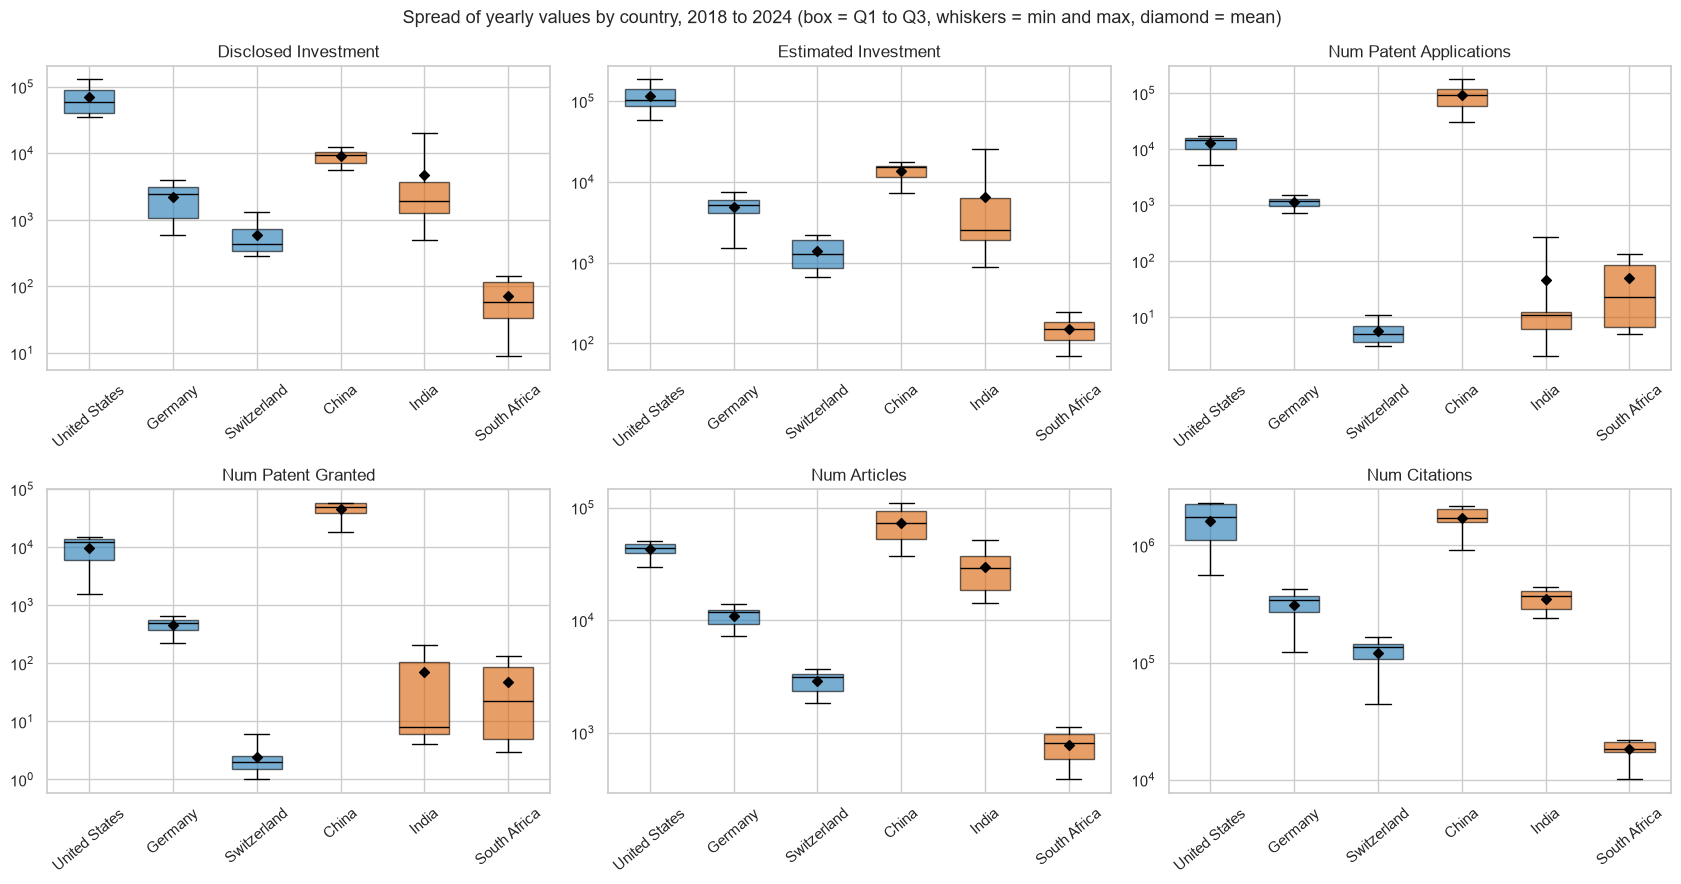

In [4]:
indicators = ["disclosed_investment", "estimated_investment",
              "num_patent_applications", "num_patent_granted",
              "num_articles", "num_citations"]
dev_set = {"United States", "Germany", "Switzerland"}

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for ax, ind in zip(axes, indicators):
    d = stats[stats["indicator"] == ind].set_index("country").loc[order]
    boxes = [{"label": c, "med": r["median"], "q1": r["Q1"], "q3": r["Q3"],
              "whislo": r["min"], "whishi": r["max"], "fliers": []}
             for c, r in d.iterrows()]
    bp = ax.bxp(boxes, showfliers=False, patch_artist=True, widths=0.6)

    for patch, c in zip(bp["boxes"], order):
        patch.set_facecolor(COLOURS["Developed"] if c in dev_set else COLOURS["Developing"])
        patch.set_alpha(0.6)
    for med in bp["medians"]:
        med.set_color("black")

    ax.scatter(range(1, 7), d["mean"], marker="D", color="black", s=25, zorder=3)
    ax.set_yscale("log")
    ax.set_title(ind.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=40)

fig.suptitle("Spread of yearly values by country, 2018 to 2024 (box = Q1 to Q3, whiskers = min and max, diamond = mean)",
             fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "summary_range_plots.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
from pathlib import Path
import pandas as pd

for f in sorted(Path("clean-pt2").glob("companies_*")):
    d = pd.read_csv(f)
    print(f"\n=== {f.name} | {d.shape[0]} rows x {d.shape[1]} cols")
    print(d.head(8).to_string())


=== companies_summary_6countries.csv | 216 rows x 5 cols
  country                    field  disclosed_investment  estimated_investment       group
0   China           Transportation                  9290                 15620  Developing
1   China                    Other                  4032                  5627  Developing
2   China  Lending and Investments                   337                   499  Developing
3   China   Information Technology                 14413                 23213  Developing
4   China              Real estate                   520                  1499  Developing
5   China                      All                118577                178057  Developing
6   China                      NLP                   820                   994  Developing
7   China                   Gaming                   122                   287  Developing

=== companies_yearly_disclosed_6countries.csv | 1996 rows x 6 cols
         country                         field  year  d

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

COLOURS = {"Developed": "#1f77b4", "Developing": "#d95f02"}
COUNTRY_COLOURS = {
    "United States": "#08519c", "Germany": "#3182bd", "Switzerland": "#9ecae1",
    "China": "#a63603", "India": "#e6550d", "South Africa": "#fdae6b",
}
YEARS = list(range(2018, 2025))

disc = pd.read_csv("clean-pt2/companies_yearly_disclosed_6countries.csv")
est = pd.read_csv("clean-pt2/companies_yearly_estimated_6countries.csv")

disc = disc[disc["year"].between(2018, 2024)].copy()
est = est[est["year"].between(2018, 2024)].copy()

disc_all = disc[disc["field"] == "All"]
est_all = est[est["field"] == "All"]

print("Disclosed investment, All rows (* = flagged incomplete)")
tbl = disc_all.assign(v=disc_all["disclosed_investment"].astype(str) + np.where(disc_all["complete"], "", "*"))
print(tbl.pivot(index="country", columns="year", values="v").reindex(columns=YEARS).fillna("missing"))

print("\nEstimated investment, All rows")
tbl = est_all.assign(v=est_all["estimated_investment"].astype(str) + np.where(est_all["complete"], "", "*"))
print(tbl.pivot(index="country", columns="year", values="v").reindex(columns=YEARS).fillna("missing"))

print("\nShare of rows flagged incomplete, by year")
print(pd.DataFrame({
    "disclosed": disc.groupby("year")["complete"].apply(lambda s: (~s).mean()),
    "estimated": est.groupby("year")["complete"].apply(lambda s: (~s).mean()),
}).round(2))

print("\nFields in the yearly files:", sorted(est["field"].unique()))

Disclosed investment, All rows (* = flagged incomplete)
year            2018   2019   2020    2021   2022   2023    2024
country                                                         
China           9394   5551  12486   11569   8579   5714    9637
Germany          585    948   1169    4007   3638   2415    2670
India           1902    503  20513    1425   3130   4355    1074
South Africa      59     15     91     140    141     51       9
Switzerland      346    346    291     889   1302    437     589
United States  38571  35690  41506  109209  69782  59585  128834

Estimated investment, All rows
year            2018    2019   2020    2021    2022   2023    2024
country                                                           
China          11141    7338  15084   17750   15600  11787   16224
Germany         3923    1507   4359    5853    5927   5160    7394
India           2541     892  25214    2080    4373   8338    1716
South Africa      70     166    150     143     200     8

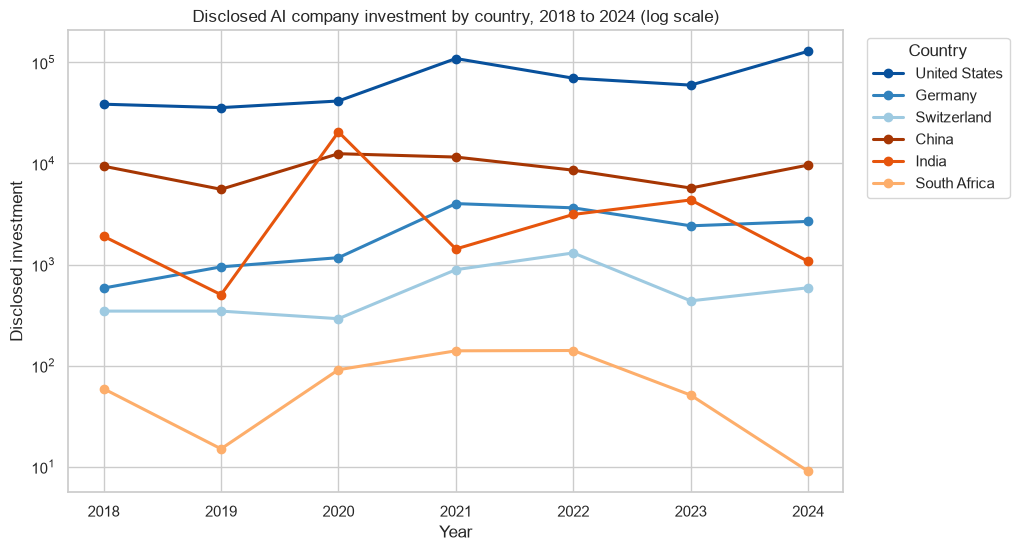

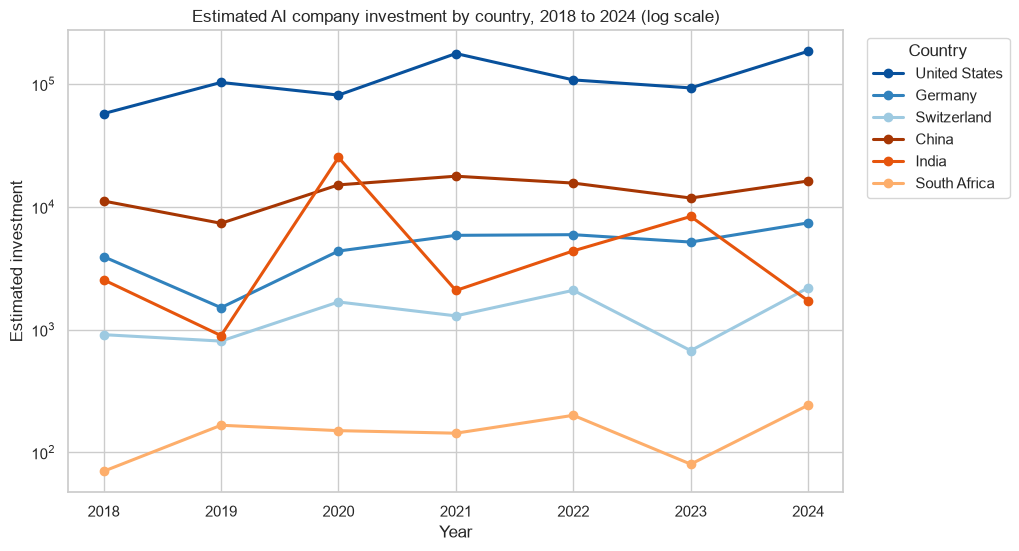

In [7]:
def plot_trend(df, value_col, title, ylabel, fname):
    wide = df.pivot(index="year", columns="country", values=value_col).reindex(YEARS)
    fig, ax = plt.subplots(figsize=(10, 6))
    for country, colour in COUNTRY_COLOURS.items():
        ax.plot(wide.index, wide[country], color=colour, marker="o", linewidth=2.2, label=country)
    ax.set_yscale("log")
    ax.set_xticks(YEARS)
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.savefig(OUT / fname, dpi=300, bbox_inches="tight")
    plt.show()


plot_trend(disc_all, "disclosed_investment",
           "Disclosed AI company investment by country, 2018 to 2024 (log scale)",
           "Disclosed investment", "companies_trend_disclosed.png")

plot_trend(est_all, "estimated_investment",
           "Estimated AI company investment by country, 2018 to 2024 (log scale)",
           "Estimated investment", "companies_trend_estimated.png")

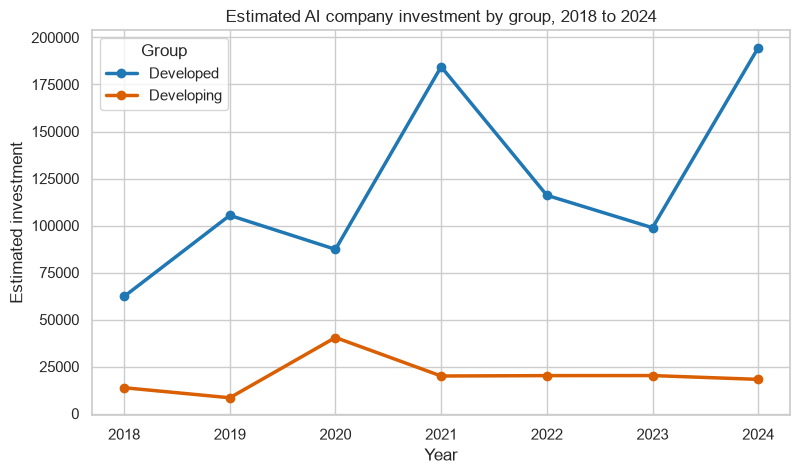

Top 6 fields: ['Software', 'Data and analytics', 'General purpose', 'Information Technology', 'Mobile, platforms & Internet services', 'Hardware']


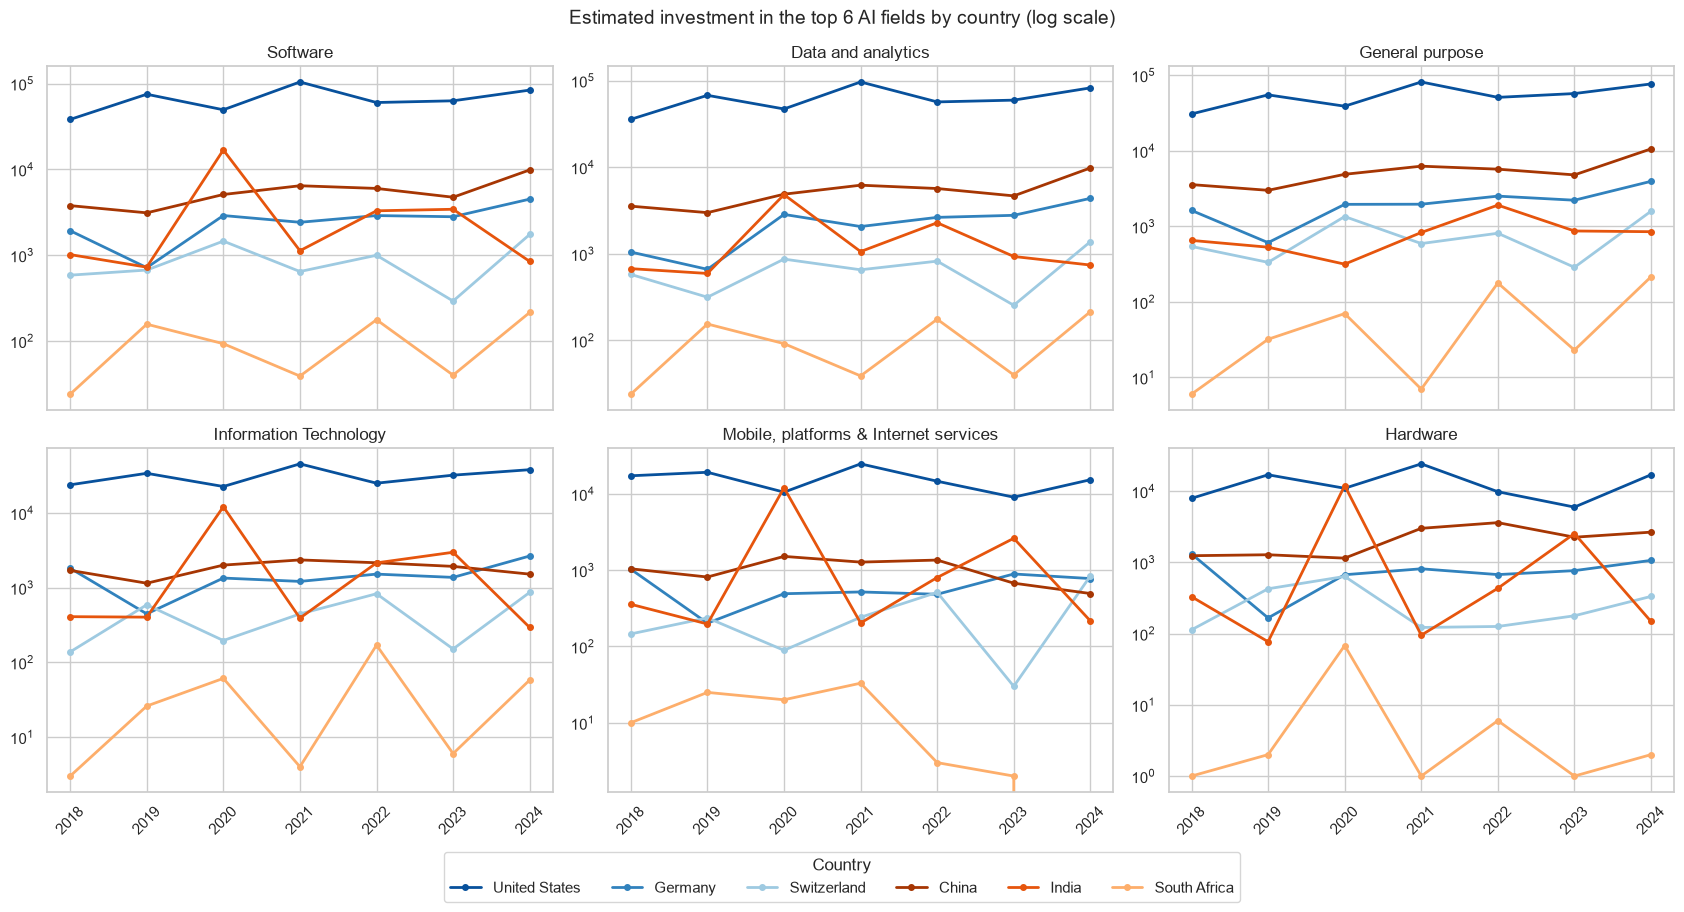

field
Data and analytics                       42
General purpose                          42
Hardware                                 42
Information Technology                   42
Mobile, platforms & Internet services    42
Software                                 42
Name: estimated_investment, dtype: int64


In [8]:
# Part 1: group level trend (estimated investment)
grp_yr = est_all.groupby(["year", "group"])["estimated_investment"].sum().unstack().reindex(YEARS)

fig, ax = plt.subplots(figsize=(9, 5))
for g in ["Developed", "Developing"]:
    ax.plot(grp_yr.index, grp_yr[g], color=COLOURS[g], marker="o", linewidth=2.5, label=g)
ax.set_xticks(YEARS)
ax.set_title("Estimated AI company investment by group, 2018 to 2024")
ax.set_xlabel("Year")
ax.set_ylabel("Estimated investment")
ax.legend(title="Group")
fig.savefig(OUT / "companies_trend_group.png", dpi=300, bbox_inches="tight")
plt.show()

# Part 2: top 6 fields by total estimated investment
skip = ["All", "Other"]
field_df = est[~est["field"].isin(skip)]
top6 = field_df.groupby("field")["estimated_investment"].sum().nlargest(6).index.tolist()
print("Top 6 fields:", top6)

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True)
axes = axes.flatten()

for ax, field in zip(axes, top6):
    d = field_df[field_df["field"] == field]
    wide = d.pivot(index="year", columns="country", values="estimated_investment").reindex(YEARS)
    for country, colour in COUNTRY_COLOURS.items():
        if country in wide.columns:
            ax.plot(wide.index, wide[country], color=colour, marker="o",
                    linewidth=2, markersize=4, label=country)
    ax.set_yscale("log")
    ax.set_title(field)
    ax.set_xticks(YEARS)
    ax.tick_params(axis="x", rotation=45)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Country", loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Estimated investment in the top 6 AI fields by country (log scale)", fontsize=14)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(OUT / "companies_field_trends.png", dpi=300, bbox_inches="tight")
plt.show()

print(field_df[field_df["field"].isin(top6)].groupby("field")["estimated_investment"].count())

In [9]:
from pathlib import Path

for f in sorted(Path("figures").glob("*")):
    print(f"{f.name:45s} {f.stat().st_size / 1024:8.0f} KB")

companies_distribution.png                         271 KB
companies_field_trends.png                         898 KB
companies_group_comparison.png                      75 KB
companies_map.html                                4715 KB
companies_top_fields.png                           136 KB
companies_total_by_country.png                      95 KB
companies_trend_disclosed.png                      271 KB
companies_trend_estimated.png                      278 KB
companies_trend_group.png                          168 KB
patents_applications_map.html                     4715 KB
patents_distribution.png                           539 KB
patents_field_growth.png                           210 KB
patents_grant_rate.png                              83 KB
patents_grant_rate_map.html                       4715 KB
patents_group_comparison.png                       106 KB
patents_totals_by_country.png                       79 KB
patents_trend_applications.png                     247 KB
patents_trend_

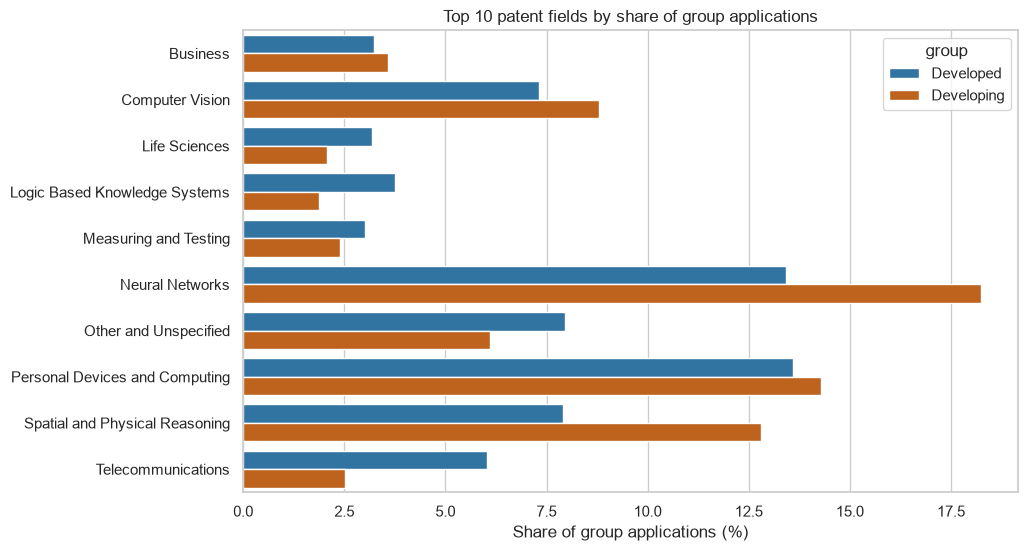

In [11]:
sns.set_theme(style="whitegrid")
OUT = Path("figures")
OUT.mkdir(exist_ok=True)
COLOURS = {"Developed": "#1f77b4", "Developing": "#d95f02"}

pat = pd.read_csv("clean-pt2/patents_summary_6countries.csv")
pat["field"] = pat["field"].str.replace(r"_+", " ", regex=True).str.strip()
fields = pat[~pat["field"].isin(["All", "Physical Sciences and Engineering"])].copy()

f = fields.groupby(["group", "field"])["num_patent_applications"].sum().reset_index()
f["share"] = f["num_patent_applications"] / f.groupby("group")["num_patent_applications"].transform("sum") * 100
top10 = f.groupby("field")["share"].sum().nlargest(10).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=f[f["field"].isin(top10)], y="field", x="share", hue="group", palette=COLOURS, ax=ax)
ax.set_title("Top 10 patent fields by share of group applications")
ax.set_xlabel("Share of group applications (%)")
ax.set_ylabel("")
fig.savefig(OUT / "patents_top_fields.png", dpi=300, bbox_inches="tight")
plt.show()